In [1]:
# Imports

import os
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models


# Dataset Overview

Dataset loaded! Shape: (825, 4)

Label distribution:
Label
Fake       550
Genuine    275
Name: count, dtype: int64

Top 10 brands by image count:
Brand Name
PlayStation    15
Lays           15
YouTube        15
Amazon         15
Gillette       15
Tesla          15
Google         15
Adidas         15
Peak milk      15
Guinness       15
Name: count, dtype: int64


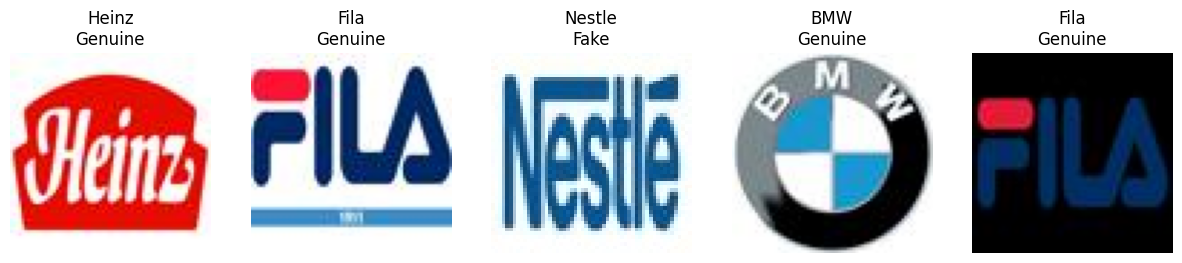

In [2]:
# Paths & Dataset

PROJECT_DIR = "/kaggle/working/fake_logo_project/"
DATASET_DIR = "/kaggle/input/fakereal-logo-detection-dataset"

os.makedirs(PROJECT_DIR, exist_ok=True)

mapping_path = os.path.join(DATASET_DIR, "file_mapping.csv")
if not os.path.exists(mapping_path):
    raise FileNotFoundError(f"{mapping_path} not found")

mapping_df = pd.read_csv(mapping_path)
print("Dataset loaded! Shape:", mapping_df.shape)


# Review Dataset

print("\nLabel distribution:")
print(mapping_df["Label"].value_counts())

print("\nTop 10 brands by image count:")
print(mapping_df["Brand Name"].value_counts().head(10))

# Quick sample visualization

def show_samples(df, n=5):
    sample_df = df.sample(n, random_state=42)
    plt.figure(figsize=(15,3))
    for i, (_, row) in enumerate(sample_df.iterrows()):
        img_path = os.path.join(DATASET_DIR, row["Filename"].replace("\\","/"))
        if not os.path.exists(img_path):
            continue
        img = cv2.imread(img_path)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(1, n, i+1)
        plt.imshow(img)
        plt.title(f"{row['Brand Name']}\n{row['Label']}")
        plt.axis("off")
    plt.show()

show_samples(mapping_df, n=5)

In [3]:
# Split Dataset by Brand

def split_dataset_small_brands(df, test_size=0.2, val_size=0.1, random_state=42):
    train_list, val_list, test_list = [], [], []

    for brand in df["Brand Name"].unique():
        brand_df = df[df["Brand Name"] == brand]
        n_samples = len(brand_df)

        if n_samples < 3:
            train_list.append(brand_df)
            continue

        stratify_test = brand_df["Label"] if n_samples * test_size >= 2 else None
        train_val, test = train_test_split(
            brand_df, test_size=test_size, stratify=stratify_test, random_state=random_state
        )

        n_train_val = len(train_val)
        if n_train_val * val_size < 1:
            train_list.append(train_val)
            test_list.append(test)
            continue

        stratify_val = train_val["Label"] if (train_val["Label"].value_counts() > 1).all() else None
        val_relative_size = val_size / (1 - test_size)
        train, val = train_test_split(
            train_val, test_size=val_relative_size, stratify=stratify_val, random_state=random_state
        )

        train_list.append(train)
        val_list.append(val)
        test_list.append(test)

    train_df = pd.concat(train_list).reset_index(drop=True)
    val_df = pd.concat(val_list).reset_index(drop=True)
    test_df = pd.concat(test_list).reset_index(drop=True)
    
    return train_df, val_df, test_df

train_df, val_df, test_df = split_dataset_small_brands(mapping_df)
print(f"\nTrain: {train_df.shape}, Val: {val_df.shape}, Test: {test_df.shape}")



Train: (583, 4), Val: (60, 4), Test: (182, 4)


In [4]:
# Add FullPath & Dataset Class

for df_split in [train_df, val_df, test_df]:
    df_split["FullPath"] = df_split["Filename"].apply(lambda x: os.path.join(DATASET_DIR, x.replace("\\","/")))

class LogoDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["FullPath"]).convert("RGB")
        label = 1 if row["Label"] == "Genuine" else 0
        if self.transform:
            img = self.transform(img)
        return img, label

In [5]:
# Transforms & DataLoaders

transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor()
])

train_dataset = LogoDataset(train_df, transform=transform)
val_dataset = LogoDataset(val_df, transform=transform)
test_dataset = LogoDataset(test_df, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

> # Training the Model

In [6]:
# Prepare DataLoaders

for df_split in [train_df, val_df, test_df]:
    df_split["FullPath"] = df_split["Filename"].apply(lambda x: os.path.join(DATASET_DIR, x.replace("\\","/")))

# Dataset & transforms

transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor()
])

train_dataset = LogoDataset(train_df, transform=transform)
val_dataset = LogoDataset(val_df, transform=transform)
test_dataset = LogoDataset(test_df, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)


# Model, Optimizer & Loss

device = "cuda" if torch.cuda.is_available() else "cpu"
model = models.resnet18(pretrained=False)
model.fc = torch.nn.Linear(model.fc.in_features, 2)  # 2 classes
model = model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = torch.nn.CrossEntropyLoss()


# Training Loop 

NUM_EPOCHS = 10
train_losses_hist, val_losses_hist = [], []
train_accs, val_accs = [], []

for epoch in range(NUM_EPOCHS):
    # Training
    
    model.train()
    train_losses = []
    correct, total = 0, 0

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = sum(train_losses) / len(train_losses)
    train_acc = correct / total
    train_losses_hist.append(train_loss)
    train_accs.append(train_acc)

    # Validation
    
    model.eval()
    val_losses = []
    all_preds, all_labels = [], []

    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_losses.append(loss.item())
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss = sum(val_losses) / len(val_losses)
    val_acc = accuracy_score(all_labels, all_preds)
    val_losses_hist.append(val_loss)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Epoch 1/10 | Train Loss: 0.8242 | Train Acc: 0.6261 | Val Loss: 1.0124 | Val Acc: 0.5000
Epoch 2/10 | Train Loss: 0.5695 | Train Acc: 0.7136 | Val Loss: 0.6182 | Val Acc: 0.7167
Epoch 3/10 | Train Loss: 0.4799 | Train Acc: 0.7633 | Val Loss: 0.5832 | Val Acc: 0.7500
Epoch 4/10 | Train Loss: 0.4739 | Train Acc: 0.7976 | Val Loss: 0.9472 | Val Acc: 0.5333
Epoch 5/10 | Train Loss: 0.4835 | Train Acc: 0.7324 | Val Loss: 1.6417 | Val Acc: 0.6167
Epoch 6/10 | Train Loss: 0.4465 | Train Acc: 0.7993 | Val Loss: 0.4894 | Val Acc: 0.7833
Epoch 7/10 | Train Loss: 0.4027 | Train Acc: 0.8182 | Val Loss: 1.3505 | Val Acc: 0.5000
Epoch 8/10 | Train Loss: 0.3968 | Train Acc: 0.8113 | Val Loss: 0.3664 | Val Acc: 0.8167
Epoch 9/10 | Train Loss: 0.3328 | Train Acc: 0.8576 | Val Loss: 0.8872 | Val Acc: 0.6500
Epoch 10/10 | Train Loss: 0.3721 | Train Acc: 0.8508 | Val Loss: 0.3226 | Val Acc: 0.8167


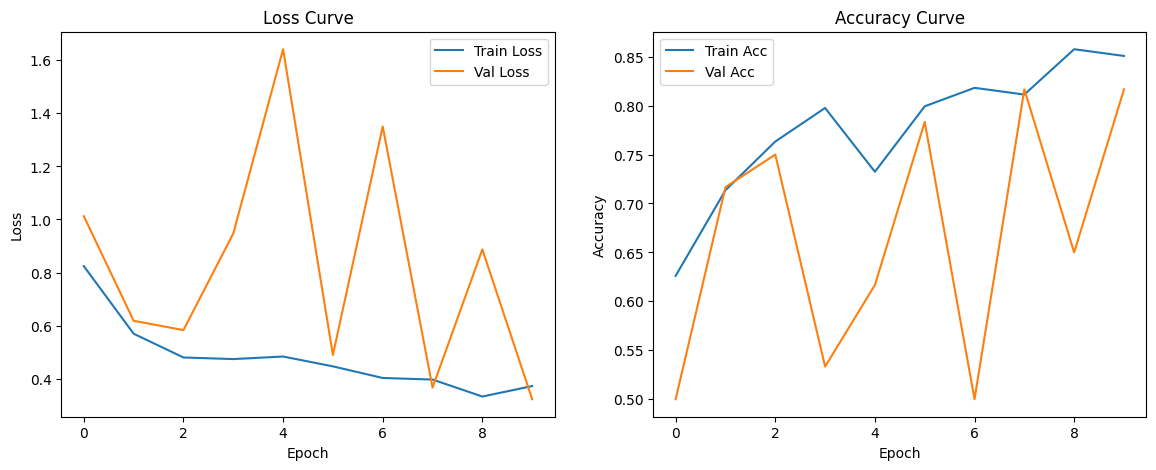


Test Loss: 0.4027 | Test Accuracy: 0.7967


In [7]:
# Plot Training & Validation Curves

import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

# Loss curves

plt.subplot(1,2,1)
plt.plot(train_losses_hist, label="Train Loss")
plt.plot(val_losses_hist, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")

# Accuracy curves

plt.subplot(1,2,2)
plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy Curve")

plt.show()


# Test Set Evaluation

model.eval()
test_losses = []
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        test_losses.append(loss.item())

        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_loss = sum(test_losses) / len(test_losses)
test_acc = accuracy_score(all_labels, all_preds)

print(f"\nTest Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.7967

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.90      0.79      0.84       121
     Class 1       0.66      0.82      0.73        61

    accuracy                           0.80       182
   macro avg       0.78      0.80      0.78       182
weighted avg       0.82      0.80      0.80       182



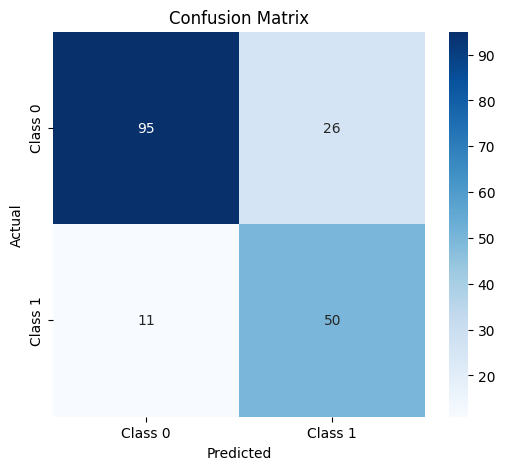

In [8]:
# Test Set Evaluation

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import torch

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Accuracy

test_acc = accuracy_score(all_labels, all_preds)
print(f"Test Accuracy: {test_acc:.4f}")

# Classification Report

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=['Class 0','Class 1']))

# Confusion Matrix

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0','Class 1'], yticklabels=['Class 0','Class 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


# Improving the Model

In [9]:
class LogoDataset(Dataset):
    def __init__(self, df, dataset_dir, transform=None):
        self.df = df.copy()
        self.dataset_dir = dataset_dir
        self.transform = transform

        # Prepare full paths
        
        self.df["FullPath"] = self.df["Filename"].apply(lambda x: os.path.join(self.dataset_dir, x.replace("\\","/")))

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["FullPath"]).convert("RGB")
        label = 1 if row["Label"] == "Genuine" else 0
        if self.transform:
            img = self.transform(img)
        return img, label


In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random


# Transforms (lighter augmentations)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.1, 0.1, 0.1, 0.05),
    transforms.ToTensor(),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])


# DataLoaders

BATCH_SIZE = 16
train_dataset = LogoDataset(train_df, DATASET_DIR, transform=train_transform)
val_dataset   = LogoDataset(val_df, DATASET_DIR, transform=val_transform)
test_dataset  = LogoDataset(test_df, DATASET_DIR, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Model

model = models.resnet18(weights="IMAGENET1K_V1")  # pretrained
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)  # 2 classes
model = model.to(device)


# Loss & Optimizer

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s]


In [11]:
# Training Loop

NUM_EPOCHS = 10
train_losses, val_losses, val_accs = [], [], []

for epoch in range(NUM_EPOCHS):
    
    # Train
    
    model.train()
    batch_losses = []
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    
    train_loss = np.mean(batch_losses)

    # Validate
    
    model.eval()
    val_batch_losses = []
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_batch_losses.append(loss.item())
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss = np.mean(val_batch_losses)
    val_acc = np.mean(np.array(all_preds) == np.array(all_labels))

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | "
          f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

Epoch 1/10 | Train Loss: 0.3988 | Val Loss: 0.3187 | Val Acc: 0.8500
Epoch 2/10 | Train Loss: 0.1026 | Val Loss: 0.1184 | Val Acc: 0.9333
Epoch 3/10 | Train Loss: 0.1013 | Val Loss: 0.0880 | Val Acc: 0.9500
Epoch 4/10 | Train Loss: 0.0979 | Val Loss: 0.1133 | Val Acc: 0.9667
Epoch 5/10 | Train Loss: 0.0974 | Val Loss: 0.1780 | Val Acc: 0.9333
Epoch 6/10 | Train Loss: 0.0886 | Val Loss: 0.0823 | Val Acc: 0.9667
Epoch 7/10 | Train Loss: 0.0253 | Val Loss: 0.1026 | Val Acc: 0.9500
Epoch 8/10 | Train Loss: 0.0233 | Val Loss: 0.0295 | Val Acc: 0.9833
Epoch 9/10 | Train Loss: 0.0588 | Val Loss: 0.1881 | Val Acc: 0.9500
Epoch 10/10 | Train Loss: 0.0495 | Val Loss: 0.1013 | Val Acc: 0.9667



Test Accuracy: 0.9725274725274725

Classification Report:
               precision    recall  f1-score   support

        Fake       0.98      0.98      0.98       121
     Genuine       0.95      0.97      0.96        61

    accuracy                           0.97       182
   macro avg       0.97      0.97      0.97       182
weighted avg       0.97      0.97      0.97       182



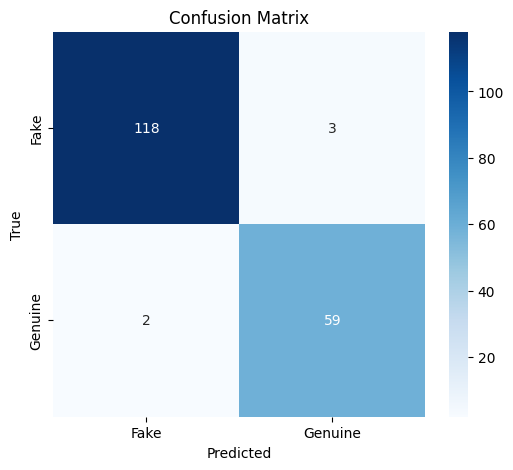

In [12]:
# Test Evaluation

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Accuracy

print("\nTest Accuracy:", accuracy_score(all_labels, all_preds))

# Classification Report

print("\nClassification Report:\n",
      classification_report(all_labels, all_preds, target_names=["Fake","Genuine"]))

# Confusion Matrix

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fake","Genuine"],
            yticklabels=["Fake","Genuine"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


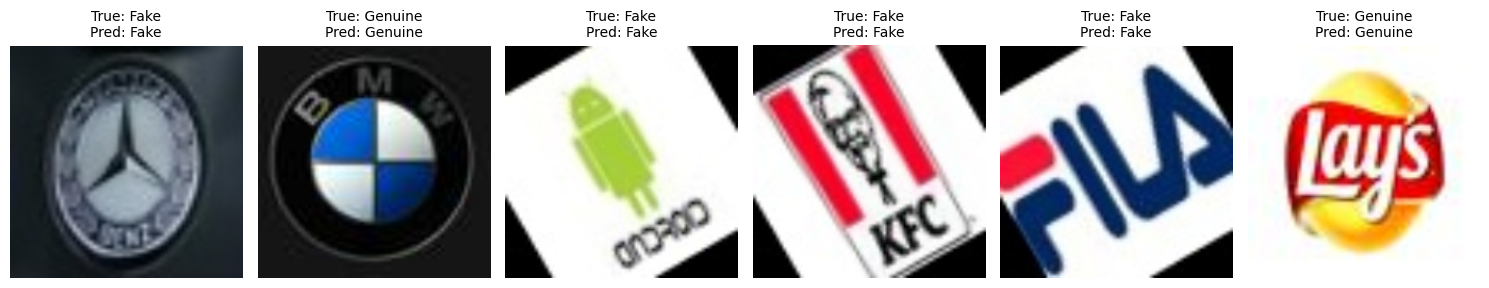

In [13]:
import random

def show_random_test_predictions(model, dataset, n=6):
    model.eval()
    plt.figure(figsize=(15, 3))
    
    indices = random.sample(range(len(dataset)), n)  # Pick n random samples
    
    for i, idx in enumerate(indices):
        img, label = dataset[idx]
        input_img = img.unsqueeze(0).to(device)
        
        with torch.no_grad():
            output = model(input_img)
            pred = torch.argmax(output, dim=1).item()
        
        # Convert tensor to image
        
        img_np = img.permute(1,2,0).numpy()
        
        plt.subplot(1, n, i+1)
        plt.imshow(img_np)
        plt.title(f"True: {'Genuine' if label==1 else 'Fake'}\nPred: {'Genuine' if pred==1 else 'Fake'}",
                  fontsize=10)
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

# Example usage

show_random_test_predictions(model, test_dataset, n=6)
